# Kiểm chứng retrieval: BM25 + SigLIP 2

Nhập query, chạy lexical và dense, rồi xem **top 10 ảnh hybrid ngay trong notebook**.

1. Trong VS Code/Jupyter, chọn interpreter/kernel của môi trường **`legalqa`**.
2. Chạy các ô từ trên xuống một lần để đọc index và nạp SigLIP 2.
3. Sửa **ô “Nhập query” ở cuối**, rồi chạy lại riêng ô đó. Mô hình và vector được giữ trong RAM.
4. Chọn `VIEW = "hybrid"`, `"lexical"` hoặc `"dense"` để đối chiếu ảnh cùng một query.

Dependencies: `requirements-dense.txt` và `ipykernel` trong môi trường đang dùng.
Nếu thiếu: `python -m pip install -r requirements-dense.txt ipykernel`.
Notebook chỉ đọc hai database có sẵn; không tạo lại caption hoặc embedding.

In [1]:
import base64
import html
import io
import math
import sqlite3
import sys
import time
import unicodedata
from contextlib import closing
from pathlib import Path

from IPython.display import HTML, display
from PIL import Image

# Chạy được từ thư mục gốc hoặc một thư mục con của dự án.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src/dense.py").is_file() and (p / "artifacts/manifest.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Hãy mở notebook trong thư mục dự án DS314_Ruttrich.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.bm25 import search as bm25_search
from src.dense import Siglip2Encoder, embedding_config, resolve_device
from src.dense_store import connect as dense_connect, get_config, load_vectors
from src.dense_store import search as dense_search
from src.lexical_store import read_manifest

DATA_ROOT = PROJECT_ROOT / "data"
MANIFEST = PROJECT_ROOT / "artifacts/manifest.csv"
LEXICAL_DB = PROJECT_ROOT / "artifacts/lexical.sqlite"
DENSE_DB = PROJECT_ROOT / "artifacts/dense.sqlite"
CACHE_DIR = PROJECT_ROOT / "artifacts/hf_cache"
DEVICE = "auto"             # auto / cuda / cpu
LOCAL_FILES_ONLY = True      # Dùng checkpoint đã tải, không truy cập mạng.

print("Python:", sys.executable)
print("Project:", PROJECT_ROOT)
print("Device:", resolve_device(DEVICE)[0])

Python: C:\Users\ADMIN\miniconda3\envs\legalqa\python.exe
Project: C:\Users\ADMIN\Documents\code\DS314_Ruttrich
Device: cuda


## Đọc index và nạp mô hình một lần

Hai nhánh phải khớp manifest về ID, đường dẫn và hash ảnh. Notebook cũng kiểm tra
caption trong FTS khớp caption hiện tại, tránh gộp các index đã cũ.
Nếu đã chỉnh ảnh, hãy tạo lại manifest và cập nhật index trước khi dùng notebook.

In [2]:
manifest_rows = read_manifest(MANIFEST)
rows_by_id = {row["imageID"]: row for row in manifest_rows}

with closing(dense_connect(DENSE_DB, readonly=True)) as db:
    dense_config = get_config(db)
    expected_config = embedding_config(
        dense_config["revision"], dense_config["inference_dtype"]
    )
    if dense_config != expected_config:
        raise ValueError("Cấu hình dense/Transformers khác lúc tạo vector. Hãy chọn đúng kernel legalqa.")
    dense_documents, image_vectors = load_vectors(
        db, manifest_rows, dense_config["dimension"]
    )

with closing(sqlite3.connect(LEXICAL_DB.resolve().as_uri() + "?mode=ro", uri=True)) as db:
    caption_records = {
        image_id: (file_path, digest, caption)
        for image_id, file_path, digest, caption in db.execute(
            "SELECT imageID, file_path, sha256, caption FROM captions"
        )
    }
    fts_records = {
        image_id: (file_path, caption)
        for image_id, file_path, caption in db.execute(
            "SELECT imageID, file_path, caption FROM caption_fts"
        )
    }

stale_ids = []
for row in manifest_rows:
    saved = caption_records.get(row["imageID"])
    if (saved is None or saved[:2] != (row["file_path"], row["sha256"])
            or fts_records.get(row["imageID"]) != (
                row["file_path"], unicodedata.normalize("NFC", saved[2])
            )):
        stale_ids.append(row["imageID"])
if stale_ids or set(fts_records) != set(rows_by_id):
    raise ValueError(
        f"BM25 không khớp manifest ({len(stale_ids)} ảnh thiếu/cũ). "
        "Cập nhật caption và chạy python -m src.bm25 build."
    )
captions_by_id = {image_id: record[2] for image_id, record in caption_records.items()}

# Chạy lại ô này với cùng cấu hình sẽ dùng lại encoder trong RAM.
encoder_key = (dense_config["revision"], DEVICE, str(CACHE_DIR), LOCAL_FILES_ONLY)
if globals().get("_loaded_encoder_key") != encoder_key:
    encoder = Siglip2Encoder(
        dense_config["revision"], DEVICE, CACHE_DIR,
        local_files_only=LOCAL_FILES_ONLY,
    )
    _loaded_encoder_key = encoder_key

print(f"Sẵn sàng: BM25 {len(fts_records):,} ảnh; dense {image_vectors.shape}.")
print("Từ đây chỉ cần sửa và chạy lại ô Nhập query ở cuối.")

Sẵn sàng: BM25 5,000 ảnh; dense (5000, 1024).
Từ đây chỉ cần sửa và chạy lại ô Nhập query ở cuối.


Loading google/siglip2-large-patch16-384@1b426889ea62b5a72bf9839009a1b184bfc9c178 on cuda (bfloat16)
[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|##########| 792/792 [00:00<00:00, 2010.15it/s]


## Gộp hai nhánh bằng Reciprocal Rank Fusion (RRF)

Với mỗi ảnh, `RRF = lexical_weight / (rrf_k + lexical_rank) + dense_weight / (rrf_k + dense_rank)`.
Hạng bắt đầu từ 1; ảnh vắng trong một danh sách không nhận điểm từ nhánh đó.
Mặc định hai trọng số bằng 1, `rrf_k = 60`, lấy 200 ứng viên mỗi nhánh rồi trả top 10.
Các giá trị này có thể chỉnh để thử nghiệm, chưa được tối ưu trên tập query có nhãn.

- **RRF và cosine:** điểm càng lớn càng tốt. RRF là điểm gộp theo thứ hạng, không phải xác suất.
- **BM25 của SQLite:** điểm càng nhỏ càng tốt, thường âm.
- Dấu **—** ở điểm/hạng nghĩa là ảnh không nằm trong danh sách ứng viên của nhánh đó.
- Caption hiện tại bằng **tiếng Anh**; lexical khớp token trực tiếp, không dịch query.
  Có thể đặt `LEXICAL_QUERY = "red shirt"` để dùng từ khóa riêng, trong khi dense vẫn dùng `QUERY` đầy đủ.
- BM25 hiện nối token bằng OR; các từ chung như “in”, “kitchen” có thể kéo nhiều ảnh lên.
  Notebook giúp quan sát vấn đề này, chưa thêm stopword hoặc rerank.

In [3]:
def reciprocal_rank_fusion(lexical_hits, dense_hits, lexical_weight=1.0,
                           dense_weight=1.0, rrf_k=60):
    weights = (lexical_weight, dense_weight)
    if (any(not math.isfinite(w) or w < 0 for w in weights)
            or sum(weights) <= 0 or not math.isfinite(rrf_k) or rrf_k <= 0):
        raise ValueError("Trọng số phải hữu hạn, không âm, tổng > 0; rrf_k > 0.")
    merged = {}
    for branch, hits, weight in (
        ("lexical", lexical_hits, lexical_weight),
        ("dense", dense_hits, dense_weight),
    ):
        for rank, hit in enumerate(hits, start=1):
            image_id = hit["imageID"]
            result = merged.setdefault(image_id, {
                "imageID": image_id,
                "file_path": hit["file_path"],
                "caption": captions_by_id.get(image_id, ""),
                "lexical_rank": None, "dense_rank": None,
                "bm25_score": None, "cosine_score": None,
                "rrf_score": 0.0,
            })
            if result["file_path"] != hit["file_path"]:
                raise ValueError(f"Đường dẫn giữa hai index khác nhau: {image_id}")
            result[f"{branch}_rank"] = rank
            score_name = "bm25_score" if branch == "lexical" else "cosine_score"
            result[score_name] = hit[score_name]
            result["rrf_score"] += weight / (rrf_k + rank)
    return sorted(
        (result for result in merged.values() if result["rrf_score"] > 0),
        key=lambda result: (-result["rrf_score"], result["imageID"]),
    )


def retrieve(query, lexical_query=None, candidate_k=200, top_k=10,
             lexical_weight=1.0, dense_weight=1.0, rrf_k=60):
    query = query.strip()
    if not query:
        raise ValueError("Query không được rỗng.")
    if top_k < 1 or candidate_k < top_k:
        raise ValueError("Cần candidate_k >= top_k >= 1.")
    # Kiểm tra tham số trước khi inference.
    reciprocal_rank_fusion([], [], lexical_weight, dense_weight, rrf_k)
    lexical_query = query if lexical_query is None else lexical_query.strip()
    if not lexical_query:
        raise ValueError("Lexical query không được rỗng; dùng None để lấy chung QUERY.")
    started = time.perf_counter()
    with closing(sqlite3.connect(LEXICAL_DB.resolve().as_uri() + "?mode=ro", uri=True)) as db:
        lexical_hits = bm25_search(db, lexical_query, top_k=candidate_k)
    # Chỉ encode câu query mới; ảnh dùng vector đã tải vào RAM.
    query_vector = encoder.text_features([query])[0]
    dense_hits = dense_search(dense_documents, image_vectors, query_vector, top_k=candidate_k)
    for rank, hit in enumerate(lexical_hits, start=1):
        hit["lexical_rank"] = rank
    for rank, hit in enumerate(dense_hits, start=1):
        hit["dense_rank"] = rank
    hybrid_hits = reciprocal_rank_fusion(
        lexical_hits, dense_hits, lexical_weight, dense_weight, rrf_k
    )
    return {
        "query": query, "lexical_query": lexical_query,
        "lexical": lexical_hits[:top_k], "dense": dense_hits[:top_k],
        "hybrid": hybrid_hits[:top_k],
        "lexical_candidate_count": len(lexical_hits),
        "dense_candidate_count": len(dense_hits),
        "elapsed_seconds": time.perf_counter() - started,
    }

## Hiển thị ảnh ngay trong output

Ảnh được đọc từ `data/`, thu nhỏ trong RAM rồi nhúng vào output. Không chỉnh sửa ảnh gốc.
Mỗi thẻ có ID, đường dẫn, điểm, thứ hạng và caption có thể bấm mở.
Output đã lưu có thể xem lại ngay cả khi chưa nạp mô hình; kết quả mẫu không chứng minh độ chính xác retrieval.

In [4]:
def thumbnail_html(file_path):
    path = (DATA_ROOT / file_path).resolve()
    if not path.is_relative_to(DATA_ROOT.resolve()):
        raise ValueError(f"Đường dẫn ảnh nằm ngoài data-root: {file_path}")
    with Image.open(path) as source:
        preview = source.convert("RGB")
    try:
        preview.thumbnail((640, 360))
        buffer = io.BytesIO()
        preview.save(buffer, format="JPEG", quality=85)
        encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
    finally:
        preview.close()
    return f'<img src="data:image/jpeg;base64,{encoded}" alt="{html.escape(file_path, quote=True)}">'


def show_results(hits, title):
    def fmt(value, spec=".4f"):
        return "—" if value is None else format(value, spec)

    cards = []
    for rank, hit in enumerate(hits, start=1):
        try:
            picture = thumbnail_html(hit["file_path"])
        except (OSError, ValueError) as exc:
            picture = f'<p>Không đọc được ảnh: {html.escape(str(exc))}</p>'
        caption = hit.get("caption", captions_by_id.get(hit["imageID"], ""))
        scores = (
            f'RRF: {fmt(hit.get("rrf_score"), ".6f")} | '
            f'Cosine: {fmt(hit.get("cosine_score"))} | '
            f'BM25: {fmt(hit.get("bm25_score"), ".5g")}'
        )
        ranks = (
            f'Hạng lexical: {fmt(hit.get("lexical_rank"), "d")} | '
            f'Hạng dense: {fmt(hit.get("dense_rank"), "d")}'
        )
        cards.append(
            '<article class="retrieval-card">'
            f'<h4>#{rank} · {html.escape(hit["imageID"])}</h4>{picture}'
            f'<div class="retrieval-path">{html.escape(hit["file_path"])}</div>'
            f'<p>{scores}<br>{ranks}</p>'
            '<details><summary>Caption BM25</summary>'
            f'<p>{html.escape(caption)}</p></details></article>'
        )
    if not cards:
        cards.append('<p>Không có ảnh khớp trong nhánh này.</p>')
    display(HTML(
        """<style>
        .retrieval-grid { display: grid; grid-template-columns: repeat(2, minmax(0, 1fr));
                          gap: 18px; max-width: 1400px; }
        .retrieval-card { border: 1px solid #8886; border-radius: 10px; padding: 12px;
                          overflow-wrap: anywhere; }
        .retrieval-card h4 { margin: 0 0 10px; }
        .retrieval-card img { width: 100%; height: auto; display: block; border-radius: 6px; }
        .retrieval-card p { font-size: 13px; line-height: 1.6; margin: 8px 0; }
        .retrieval-path { font-size: 12px; opacity: .7; margin-top: 6px; }
        @media (max-width: 720px) { .retrieval-grid { grid-template-columns: 1fr; } }
        </style>"""
        f'<h3>{html.escape(title)}</h3><div class="retrieval-grid">'
        + "".join(cards) + "</div>"
    ))

## Nhập query — sửa và chạy lại ô dưới đây

- `QUERY`: câu mô tả dùng cho dense; mặc định cũng dùng cho lexical.
- `LEXICAL_QUERY`: `None` để dùng chung query, hoặc từ khóa tiếng Anh như `"red shirt"`.
- `VIEW`: `"hybrid"` (mặc định), `"lexical"` hoặc `"dense"`.
- `SHOW_COMPARISON = True`: hiện thêm top 10 của hai nhánh riêng để so sánh.
- Có thể chỉnh hai trọng số RRF; đặt một trọng số bằng 0 để chỉ đóng góp nhánh còn lại.

Sau mỗi lần sửa query, kết quả cũ của ô này sẽ được thay bằng kết quả mới khi chạy ô.

Dense query: Red shirt guy in kitchen
Lexical query: Red shirt guy in kitchen
Ứng viên: lexical=200, dense=200 | Thời gian truy vấn: 0.136s



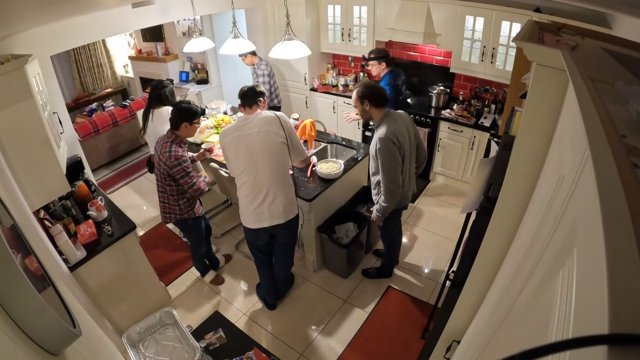
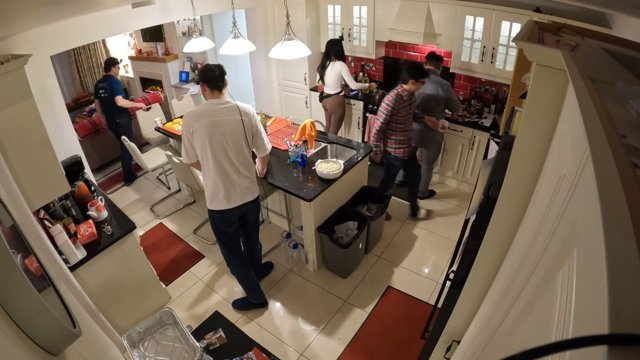
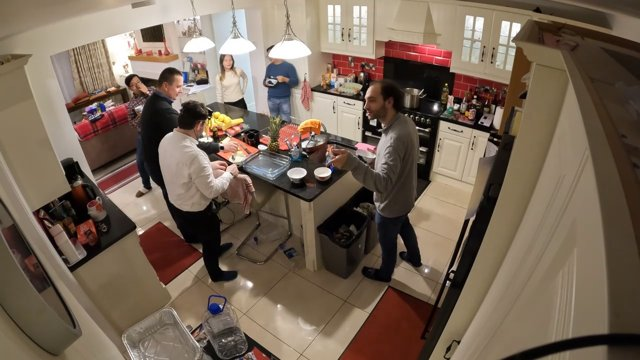
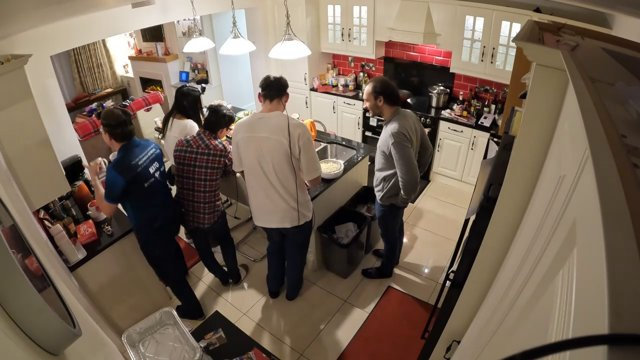
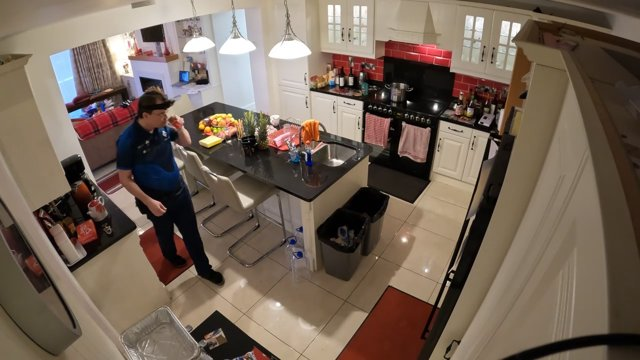
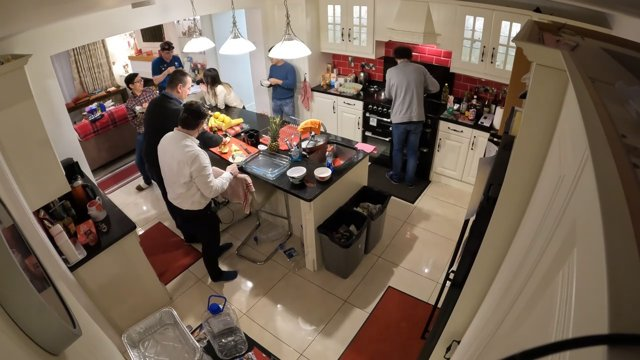
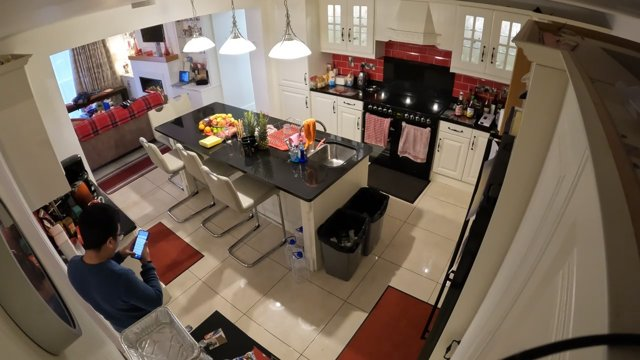
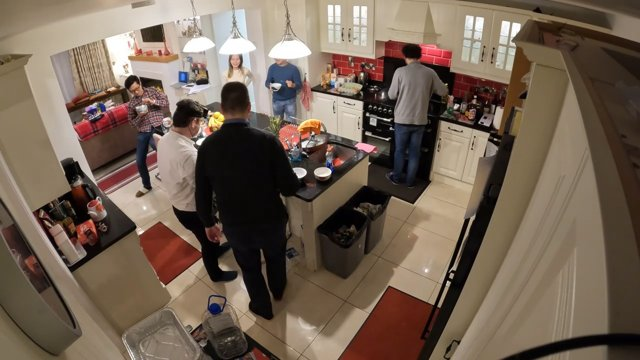
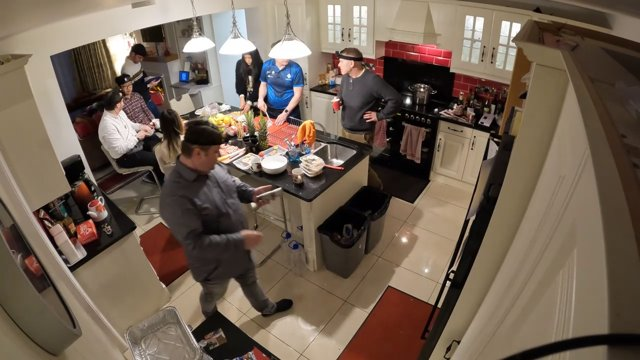
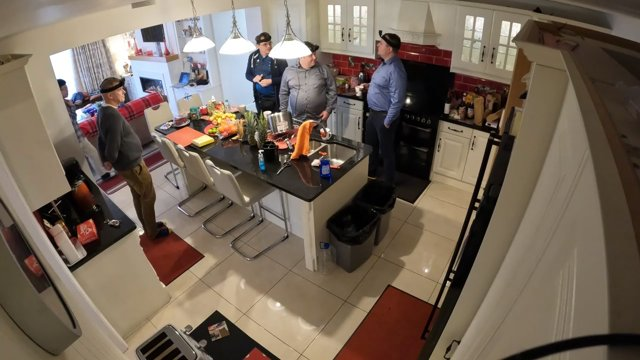

In [5]:
QUERY = "Red shirt guy in kitchen"     # <<< Nhập query tại đây.
LEXICAL_QUERY = None                   # Ví dụ: "red shirt"; None = dùng chung QUERY.
TOP_K = 10
CANDIDATE_K = 200
LEXICAL_WEIGHT = 1.0
DENSE_WEIGHT = 1.0
RRF_K = 60
VIEW = "hybrid"                       # hybrid / lexical / dense
SHOW_COMPARISON = False

if VIEW not in {"hybrid", "lexical", "dense"}:
    raise ValueError("VIEW phải là hybrid, lexical hoặc dense.")

retrieval = retrieve(
    QUERY, lexical_query=LEXICAL_QUERY, candidate_k=CANDIDATE_K, top_k=TOP_K,
    lexical_weight=LEXICAL_WEIGHT, dense_weight=DENSE_WEIGHT, rrf_k=RRF_K,
)
print(f"Dense query: {retrieval['query']}")
print(f"Lexical query: {retrieval['lexical_query']}")
print(
    f"Ứng viên: lexical={retrieval['lexical_candidate_count']}, "
    f"dense={retrieval['dense_candidate_count']} | "
    f"Thời gian truy vấn: {retrieval['elapsed_seconds']:.3f}s"
)
if retrieval["lexical_candidate_count"] == 0:
    print("Lexical không có token khớp; hybrid chỉ có đóng góp từ dense (nếu dense_weight > 0).")
show_results(retrieval[VIEW], f"Top {TOP_K} · {VIEW.upper()} · {QUERY}")
if SHOW_COMPARISON:
    for branch in ("lexical", "dense"):
        if branch != VIEW:
            show_results(retrieval[branch], f"Top {TOP_K} · {branch.upper()} · {QUERY}")